# Used Car Price Prediction — Data Science Intern Project

This notebook builds a machine learning workflow to predict used car resale prices in India (in ₹ Lakhs). 
**Naming Convention:** All user-defined variables, DataFrame column names, functions, and saved files strictly avoid using underscores (`_`).

## Step 1: Import Libraries and Generate Synthetic Dataset
We generate a realistic dataset of 1,500 Indian used cars across 6 popular brands (`Maruti`, `Hyundai`, `Tata`, `Honda`, `Toyota`, `Mahindra`).

In [1]:
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

np.random.seed(42)
samplesize = 1500

brandlist = ['Maruti', 'Hyundai', 'Tata', 'Honda', 'Toyota', 'Mahindra']
fuellist = ['Petrol', 'Diesel', 'CNG', 'Electric']
translist = ['Manual', 'Automatic']

carbrand = np.random.choice(brandlist, size=samplesize)
modelyear = np.random.randint(2010, 2027, size=samplesize)
kmdriven = np.random.randint(5000, 200000, size=samplesize)
fueltype = np.random.choice(fuellist, size=samplesize, p=[0.45, 0.35, 0.12, 0.08])
transmission = np.random.choice(translist, size=samplesize, p=[0.65, 0.35])
ownercount = np.random.choice([1, 2, 3], size=samplesize, p=[0.70, 0.22, 0.08])

# Base valuation logic in Lakhs (INR)
brandbase = {'Maruti': 6.5, 'Hyundai': 8.0, 'Tata': 8.5, 'Honda': 9.5, 'Toyota': 14.5, 'Mahindra': 12.5}
fuelbonus = {'Petrol': 0.0, 'Diesel': 1.2, 'CNG': 0.4, 'Electric': 2.5}
transbonus = {'Manual': 0.0, 'Automatic': 1.5}

sellingprice = []
for idx in range(samplesize):
    baseval = brandbase[carbrand[idx]]
    age = 2026 - modelyear[idx]
    agefactor = (0.91 ** age)
    kmfactor = max(0.4, 1.0 - (kmdriven[idx] / 320000.0))
    ownerpenalty = (ownercount[idx] - 1) * 0.45
    
    estimated = (baseval * agefactor * kmfactor) + fuelbonus[fueltype[idx]] + transbonus[transmission[idx]] - ownerpenalty
    noise = np.random.normal(0, 0.35)
    finalval = max(1.10, round(estimated + noise, 2))
    sellingprice.append(finalval)

cardata = pd.DataFrame({
    'carbrand': carbrand,
    'modelyear': modelyear,
    'kmdriven': kmdriven,
    'fueltype': fueltype,
    'transmission': transmission,
    'ownercount': ownercount,
    'sellingprice': sellingprice
})

print('Dataset Shape:', cardata.shape)
cardata.head(10)

Dataset Shape: (1500, 7)


,carbrand,modelyear,kmdriven,fueltype,transmission,ownercount,sellingprice
0,Honda,2015,49014,CNG,Manual,1,3.22
1,Toyota,2011,147810,Diesel,Manual,1,3.02
2,Tata,2021,99333,Petrol,Manual,1,3.97
3,Toyota,2014,183570,Diesel,Automatic,1,4.48
4,Toyota,2021,16120,Diesel,Manual,1,10.21
5,Hyundai,2026,144839,Petrol,Manual,2,4.24
6,Tata,2026,27852,Petrol,Manual,1,8.40
7,Tata,2019,84239,Electric,Manual,1,5.49
8,Tata,2026,137001,CNG,Automatic,1,7.24
9,Toyota,2024,96575,CNG,Automatic,1,10.48


## Step 2: Exploratory Data Analysis (EDA)
Inspect summary statistics, missing values, and brand-wise average resale prices.

In [2]:
print('Missing Values Check:')
print(cardata.isnull().sum())

print('\nSummary Statistics:')
print(cardata.describe().round(2))

brandavg = cardata.groupby('carbrand')['sellingprice'].mean().sort_values(ascending=False)
print('\nAverage Selling Price by Brand (in Lakhs):')
print(brandavg.round(2))

Missing Values Check:
carbrand        0
modelyear       0
kmdriven        0
fueltype        0
transmission    0
ownercount      0
sellingprice    0
dtype: int64

Summary Statistics:
       modelyear   kmdriven  ownercount  sellingprice
count    1500.00    1500.00     1500.00       1500.00
mean     2018.00  103029.38        1.39          4.52
std         4.91   56461.22        0.62          2.38
min      2010.00    5138.00        1.00          1.10
25%      2014.00   53963.00        1.00          2.78
50%      2018.00  103642.00        1.00          4.09
75%      2022.00  153111.50        2.00          5.79
max      2026.00  199994.00        3.00         16.61

Average Selling Price by Brand (in Lakhs):
carbrand
Toyota      5.96
Mahindra    5.60
Honda       4.45
Tata        3.92
Hyundai     3.84
Maruti      3.38
Name: sellingprice, dtype: float64


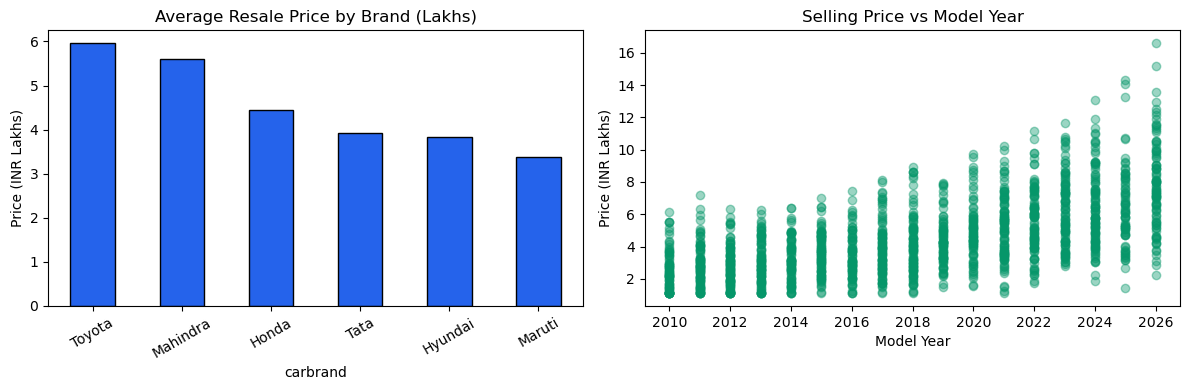

In [3]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
brandavg.plot(kind='bar', color='#2563eb', edgecolor='black')
plt.title('Average Resale Price by Brand (Lakhs)')
plt.ylabel('Price (INR Lakhs)')
plt.xticks(rotation=30)

plt.subplot(1, 2, 2)
plt.scatter(cardata['modelyear'], cardata['sellingprice'], alpha=0.4, color='#059669')
plt.title('Selling Price vs Model Year')
plt.xlabel('Model Year')
plt.ylabel('Price (INR Lakhs)')

plt.tight_layout()
plt.show()

## Step 3: Preprocessing Pipeline & Model Training
We split the dataset into training and testing subsets and compare **Multiple Linear Regression** with **Random Forest Regressor**.

In [4]:
features = cardata[['carbrand', 'modelyear', 'kmdriven', 'fueltype', 'transmission', 'ownercount']]
target = cardata['sellingprice']

xtrain, xtest, ytrain, ytest = train_test_split(features, target, test_size=0.2, random_state=42)

categoricalcols = ['carbrand', 'fueltype', 'transmission']
preprocessor = ColumnTransformer(
    transformers=[
        ('catencoder', OneHotEncoder(handle_unknown='ignore'), categoricalcols)
    ],
    remainder='passthrough'
)

# 1. Linear Regression Pipeline
linearpipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

linearpipeline.fit(xtrain, ytrain)
linearpreds = linearpipeline.predict(xtest)

linearr2 = r2_score(ytest, linearpreds)
linearmae = mean_absolute_error(ytest, linearpreds)
linearrmse = np.sqrt(mean_squared_error(ytest, linearpreds))

# 2. Random Forest Regressor Pipeline
forestpipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=120, random_state=42))
])

forestpipeline.fit(xtrain, ytrain)
forestpreds = forestpipeline.predict(xtest)

forestr2 = r2_score(ytest, forestpreds)
forestmae = mean_absolute_error(ytest, forestpreds)
forestrmse = np.sqrt(mean_squared_error(ytest, forestpreds))

comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest Regressor'],
    'R2Score': [round(linearr2, 4), round(forestr2, 4)],
    'MAE (Lakhs)': [round(linearmae, 4), round(forestmae, 4)],
    'RMSE (Lakhs)': [round(linearrmse, 4), round(forestrmse, 4)]
})

print('Model Evaluation Summary:')
print(comparison.to_string(index=False))

Model Evaluation Summary:
                  Model  R2Score  MAE (Lakhs)  RMSE (Lakhs)
      Linear Regression   0.8929       0.6055        0.8532
Random Forest Regressor   0.9281       0.5061        0.6991


## Step 4: Custom Prediction Function & Model Serialization
Define `predictprice()` with zero underscores and export the trained pipeline to `carpricemodel.pkl`.

In [5]:
def predictprice(brandval, yearval, kmval, fuelval, transval, ownerval):
    sampleinput = pd.DataFrame([{
        'carbrand': brandval,
        'modelyear': yearval,
        'kmdriven': kmval,
        'fueltype': fuelval,
        'transmission': transval,
        'ownercount': ownerval
    }])
    predictedval = forestpipeline.predict(sampleinput)[0]
    return round(float(predictedval), 2)

# Test prediction
sampleestimate = predictprice('Hyundai', 2021, 38000, 'Petrol', 'Automatic', 1)
print(f'Estimated Price for 2021 Hyundai (Automatic, Petrol, 38k km): Rs. {sampleestimate} Lakhs')

# Save trained model pipeline
with open('carpricemodel.pkl', 'wb') as modelfile:
    pickle.dump(forestpipeline, modelfile)

print('Saved trained pipeline as carpricemodel.pkl')

Estimated Price for 2021 Hyundai (Automatic, Petrol, 38k km): Rs. 6.44 Lakhs
Saved trained pipeline as carpricemodel.pkl
